In [1]:
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import adjusted_rand_score

In [7]:
data = pd.read_excel("/content/Data_User_Modeling_Dataset_Hamdi Tolga KAHRAMAN.xls")
print("Dataset loaded successfully")
data.head()

Dataset loaded successfully


,Data Set Characteristics: Multivariate,Unnamed: 1,Attribute Information:
0,Number of Instances: 403,NaN,STG (The degree of study time for goal object ...
1,Area: Education,NaN,SCG (The degree of repetition number of user f...
2,Attribute Characteristics: Real,NaN,STR (The degree of study time of user for rela...
3,Number of Attributes: 5,NaN,LPR (The exam performance of user for related ...
4,Associated Tasks: Classification,NaN,PEG (The exam performance of user for goal obj...


In [23]:
data.shape

(258, 9)

In [24]:
data.describe()

,STG,SCG,STR,LPR,PEG,Unnamed: 6,Unnamed: 7
count,258.000000,258.000000,258.000000,258.000000,258.000000,0.0,0.0
mean,0.371147,0.355674,0.468004,0.432713,0.458539,NaN,NaN
std,0.210271,0.211962,0.245940,0.248108,0.255211,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.240750,0.210000,0.291250,0.250000,0.250000,NaN,NaN
50%,0.327000,0.302500,0.490000,0.330000,0.500000,NaN,NaN
75%,0.495000,0.497500,0.690000,0.647500,0.660000,NaN,NaN
max,0.990000,0.900000,0.950000,0.990000,0.930000,NaN,NaN


In [ ]:
data.info()

In [ ]:
data.isnull().sum()

In [8]:
xls_file = pd.ExcelFile("/content/Data_User_Modeling_Dataset_Hamdi Tolga KAHRAMAN.xls")
print("Sheet names:", xls_file.sheet_names)

Sheet names: ['Information', 'Training_Data', 'Test_Data']


In [10]:
data = pd.read_excel("/content/Data_User_Modeling_Dataset_Hamdi Tolga KAHRAMAN.xls", sheet_name="Training_Data")
print("Training dataset loaded successfully!")
data.head()

Training dataset loaded successfully!


,STG,SCG,STR,LPR,PEG,UNS,Unnamed: 6,Unnamed: 7,Attribute Information:
0,0.00,0.00,0.00,0.00,0.00,very_low,NaN,NaN,STG (The degree of study time for goal object ...
1,0.08,0.08,0.10,0.24,0.90,High,NaN,NaN,SCG (The degree of repetition number of user f...
2,0.06,0.06,0.05,0.25,0.33,Low,NaN,NaN,STR (The degree of study time of user for rela...
3,0.10,0.10,0.15,0.65,0.30,Middle,NaN,NaN,LPR (The exam performance of user for related ...
4,0.08,0.08,0.08,0.98,0.24,Low,NaN,NaN,PEG (The exam performance of user for goal obj...


In [13]:
# Strip any whitespace from the column headers themselves
data.columns = data.columns.str.strip()

# Keep only the relevant columns
cleaned_data = data[['STG', 'SCG', 'STR', 'LPR', 'PEG', 'UNS']].copy()

# Strip any accidental whitespace from categorical labels in the target column 'UNS'
cleaned_data['UNS'] = cleaned_data['UNS'].str.strip()

print("Cleaned Data Info:")
print(cleaned_data.info())
print("\nUnique target values in UNS:", cleaned_data['UNS'].unique())
cleaned_data.head()

Cleaned Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 258 entries, 0 to 257
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   STG     258 non-null    float64
 1   SCG     258 non-null    float64
 2   STR     258 non-null    float64
 3   LPR     258 non-null    float64
 4   PEG     258 non-null    float64
 5   UNS     258 non-null    object 
dtypes: float64(5), object(1)
memory usage: 12.2+ KB
None

Unique target values in UNS: ['very_low' 'High' 'Low' 'Middle']


,STG,SCG,STR,LPR,PEG,UNS
0,0.00,0.00,0.00,0.00,0.00,very_low
1,0.08,0.08,0.10,0.24,0.90,High
2,0.06,0.06,0.05,0.25,0.33,Low
3,0.10,0.10,0.15,0.65,0.30,Middle
4,0.08,0.08,0.08,0.98,0.24,Low


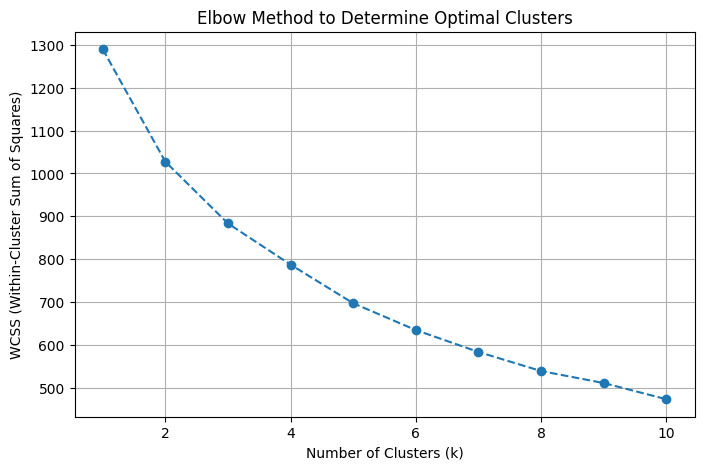

In [15]:
# 1. Extract features
X = cleaned_data[['STG', 'SCG', 'STR', 'LPR', 'PEG']]

# 2. Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Use Elbow Method to find optimal k
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# 4. Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method to Determine Optimal Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

Silhouette Score (k=4): 0.1922 (Higher is better, range: -1 to 1)
Davies-Bouldin Score (k=4): 1.5793 (Lower is better)


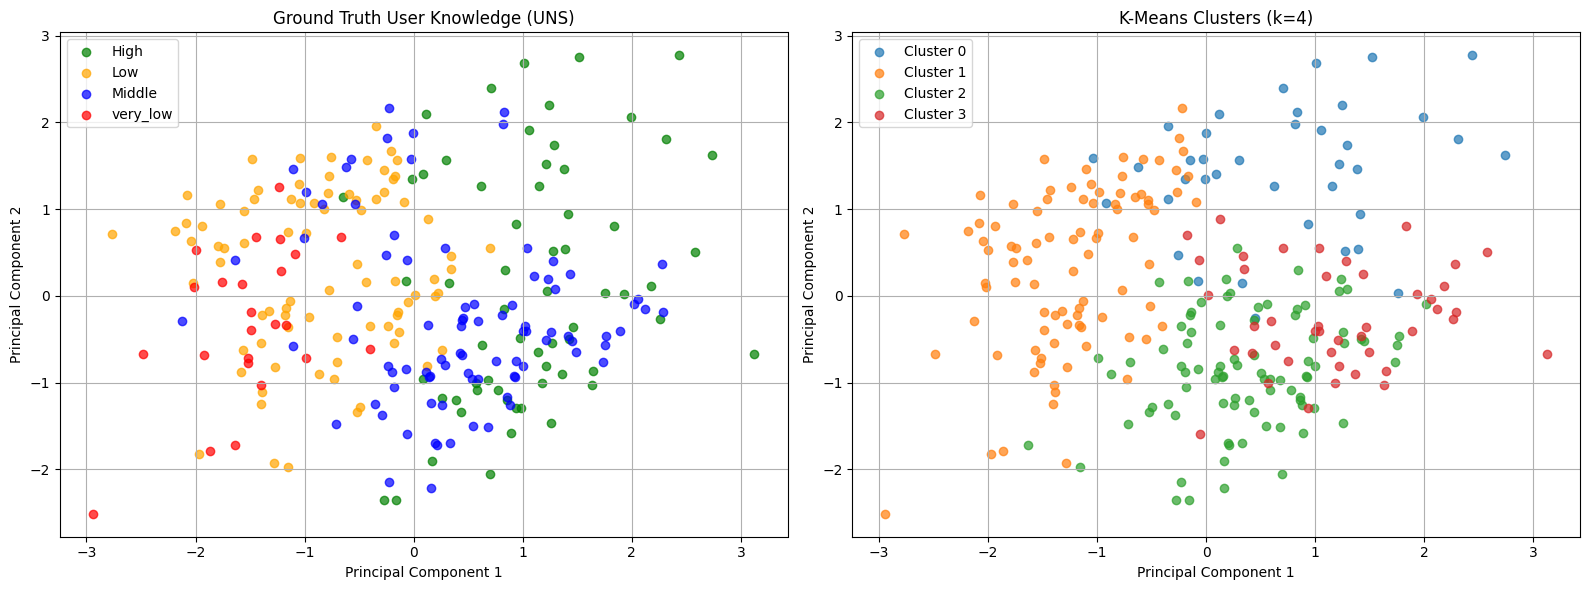

In [17]:
# 1. Fit KMeans with k = 4
kmeans = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
cleaned_data['Cluster'] = kmeans.fit_predict(X_scaled)

# 2. Evaluate using unsupervised metrics
sil_score = silhouette_score(X_scaled, cleaned_data['Cluster'])
db_score = davies_bouldin_score(X_scaled, cleaned_data['Cluster'])
print(f"Silhouette Score (k=4): {sil_score:.4f} (Higher is better, range: -1 to 1)")
print(f"Davies-Bouldin Score (k=4): {db_score:.4f} (Lower is better)")

# 3. PCA for 2D Visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
cleaned_data['PCA1'] = X_pca[:, 0]
cleaned_data['PCA2'] = X_pca[:, 1]

# Plot ground truth vs K-Means clusters side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Ground Truth plot
colors = {'very_low': 'red', 'Low': 'orange', 'Middle': 'blue', 'High': 'green'}
for label, group in cleaned_data.groupby('UNS'):
    axes[0].scatter(group['PCA1'], group['PCA2'], label=label, color=colors.get(label, 'black'), alpha=0.7)
axes[0].set_title('Ground Truth User Knowledge (UNS)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()
axes[0].grid(True)

# KMeans cluster plot
for cluster in range(4):
    group = cleaned_data[cleaned_data['Cluster'] == cluster]
    axes[1].scatter(group['PCA1'], group['PCA2'], label=f'Cluster {cluster}', alpha=0.7)
axes[1].set_title('K-Means Clusters (k=4)')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [19]:
# Calculate Adjusted Rand Index to compare clusters with actual UNS labels
ari_score = adjusted_rand_score(cleaned_data['UNS'], cleaned_data['Cluster'])
print(f"Adjusted Rand Index (ARI): {ari_score:.4f} (1.0 indicates perfect agreement)")

Adjusted Rand Index (ARI): 0.1709 (1.0 indicates perfect agreement)


In [21]:
# Calculate and display model evaluation metrics: Silhouette Score, WCSS (Inertia), Davies-Bouldin Index
# We use cleaned_data['Cluster'] since the variable 'labels' is not defined
cluster_labels = cleaned_data['Cluster']

score = silhouette_score(X_scaled, cluster_labels)
print("Silhouette Score:", score)

wcss = kmeans.inertia_
print("WCSS (Inertia):", wcss)

db_score = davies_bouldin_score(X_scaled, cluster_labels)
print("Davies-Bouldin Index:", db_score)

Silhouette Score: 0.19215981580643018
WCSS (Inertia): 787.2487014812507
Davies-Bouldin Index: 1.57934638578819
